<a href="https://colab.research.google.com/github/MartinSamas/cifar10_cnn/blob/main/cifar10_cnn_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
import tensorflow_datasets as tfds

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

np.set_printoptions(precision=4)
tf.keras.utils.set_random_seed(42)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DATA_DIR = '/content/drive/MyDrive/4IZ175/tensorflow_datasets'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def plot_history(history, title=''):
    h = history.history
    epochs = range(1, len(h['loss']) + 1)
    best = int(np.argmin(h['val_loss'])) + 1   # epocha s minimálnym val_loss

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, h['accuracy'], 'o-', ms=3, label='train')
    axes[0].plot(epochs, h['val_accuracy'], 'o-', ms=3, label='validation')
    axes[0].set_title('Accuracy')
    axes[0].set_ylabel('accuracy')

    axes[1].plot(epochs, h['loss'], 'o-', ms=3, label='train')
    axes[1].plot(epochs, h['val_loss'], 'o-', ms=3, label='validation')
    axes[1].set_title('Loss')
    axes[1].set_ylabel('loss')

    for ax in axes:
        ax.axvline(best, color='gray', ls='--', lw=1, label=f'min val_loss (epocha {best})')
        ax.set_xlabel('epocha')
        ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

# Načítanie dát

In [ ]:
(ds_train, ds_val, ds_test), ds_info = tfds.load(
    'cifar10',
    split=['train[:40000]', 'train[40000:50000]', 'test'],
    as_supervised=True,
    with_info=True,
    data_dir=DATA_DIR
)

print(ds_info.features)
print("Train:", ds_train.cardinality())
print("Val:  ", ds_val.cardinality())
print("Test: ", ds_test.cardinality())

FeaturesDict({
    'id': Text(shape=(), dtype=string),
    'image': Image(shape=(32, 32, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=10),
})
Train: tf.Tensor(40000, shape=(), dtype=int64)
Val:   tf.Tensor(10000, shape=(), dtype=int64)
Test:  tf.Tensor(10000, shape=(), dtype=int64)


# Vizualizovanie datasetu

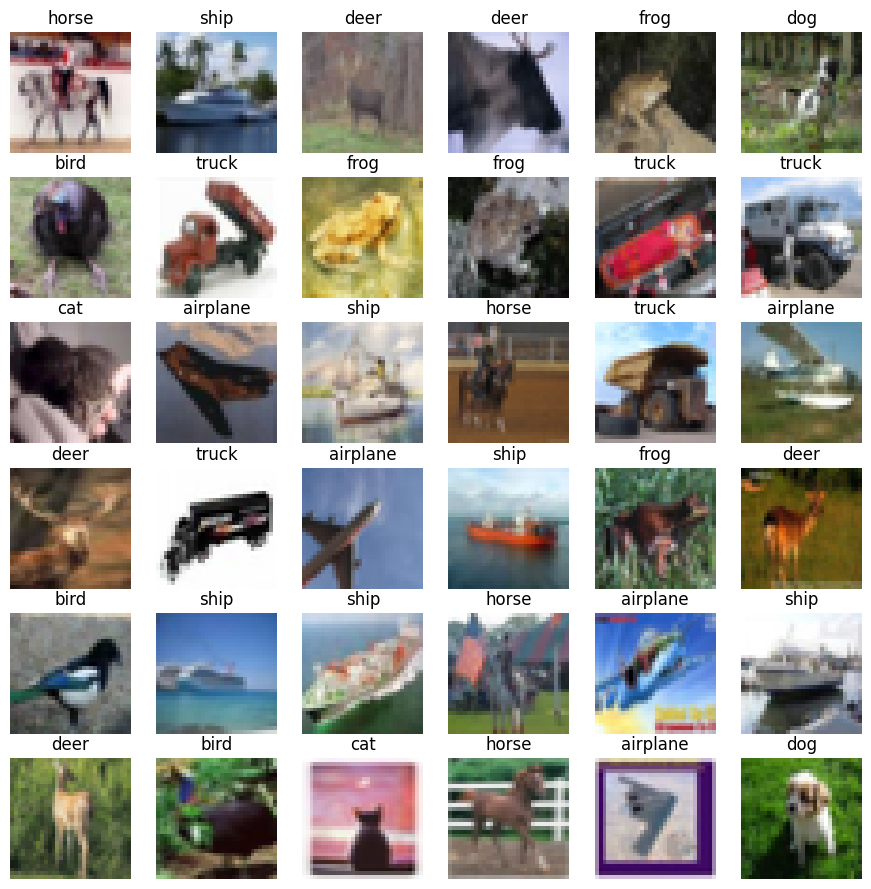

In [ ]:
plt.figure(figsize=(12,12))

for images, labels in ds_train.batch(36).take(1):
  for i in range(36):
    ax = plt.subplot(6,6,i+1)
    plt.imshow(images[i])
    plt.title(ds_info.features['label'].int2str(labels[i]))
    plt.axis('off')


## Rozloženie datasetov

train: [4075 3995 4006 3991 4021 4011 4013 4003 3976 3909]
val:   [ 925 1005  994 1009  979  989  987  997 1024 1091]
test:   [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


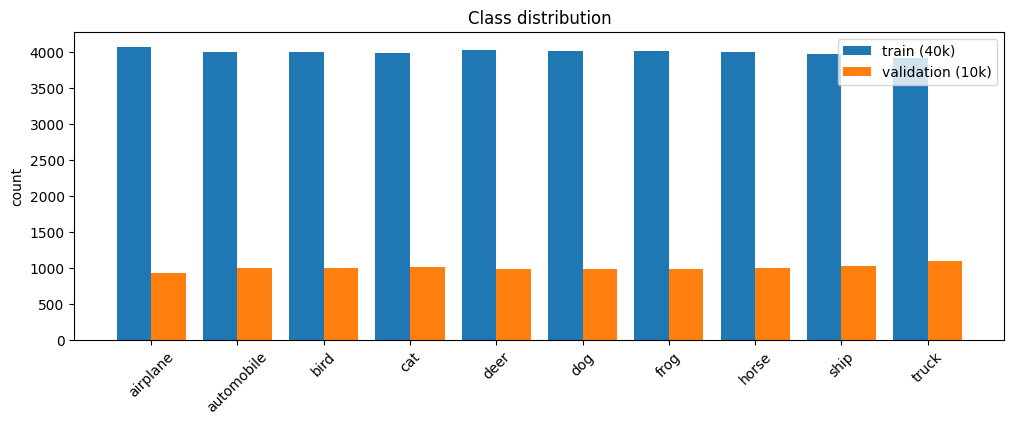

In [ ]:
class_names = ds_info.features['label'].names
train_labels = np.array([l.numpy() for _, l in ds_train])
val_labels   = np.array([l.numpy() for _, l in ds_val])
test_labels   = np.array([l.numpy() for _, l in ds_test])
print("train:", np.bincount(train_labels))
print("val:  ", np.bincount(val_labels))
print("test:  ", np.bincount(test_labels))

x = np.arange(10)
plt.figure(figsize=(12, 4))
plt.bar(x - 0.2, np.bincount(train_labels), width=0.4, label='train (40k)')
plt.bar(x + 0.2, np.bincount(val_labels),   width=0.4, label='validation (10k)')
plt.xticks(x, class_names, rotation=45)
plt.ylabel('count'); plt.legend(); plt.title('Class distribution')
plt.show()

Rozdelenie tried v train (40k) a validation (10k) je približne rovnomerné (~4000 / ~1000 na triedu, s odchýlkami len v desiatkach); testovacia množina obsahuje presne 1000 obrázkov pre každú triedu. Preto nie je potrebné žiadne rebalancovanie ani váženie tried a accuracy predstavuje vhodnú metriku na vyhodnotenie.

# Predspracovanie dát

### Normalizácia
Pixelové hodnoty sú konvertované z `uint8` (0–255) na `float32` v rozsahu 0–1, čo robí trénovanie rýchlejšie a stabilnejšie.

### Pipeline

**Trénovacia množina:** `map(normalize)` -> `cache()` -> `shuffle(40000)` -> `batch(128)` -> `prefetch()`
- `cache()` uloží normalizované dáta do RAM po prvej epoche, takže ďalšie epochy ich nemusia znova načítavať a spracovávať.
- `shuffle(40000)` s bufferom vo veľkosti trénovacej množiny dáta úplne zamieša, a keďže je za `cache()`, v každej epoche inak.
- `batch(128)` je kompromis medzi rýchlosťou trénovania a šumom gradientu. Jedna epocha má 40000 / 128 = 312.5 -> 313 batchov.
- `prefetch(AUTOTUNE)` pripraví ďalší batch na CPU, zatiaľ čo GPU trénuje na aktuálnom.

**Validačná a testovacia množina:** `map(normalize)` -> `cache()` -> `batch(256)` -> `prefetch()`
- Nie sú zamiešané, pretože sa na nich netrénuje a metriky nezávisia od poradia. Matica zámen navyše vyžaduje pevné poradie, aby predikcie sedeli so skutočnými labelmi.
- Používame väčší batch (256), pretože batch size nemá vplyv na výsledok vyhodnotenia, len na rýchlosť a pamäť.

### Labely
Zostávajú ako celé čísla 0–9, model preto používa loss `sparse_categorical_crossentropy`.

In [ ]:
print(ds_train.element_spec)

(TensorSpec(shape=(32, 32, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))


In [ ]:
def normalize(image, label):
  return tf.cast(image, tf.float32) / 255, label

AUTOTUNE = tf.data.AUTOTUNE

train_ds = (ds_train
                .map(normalize, num_parallel_calls=AUTOTUNE)
                .cache()
                .shuffle(40000)
                .batch(128)
                .prefetch(AUTOTUNE)
            )

val_ds = (ds_val.map(normalize, num_parallel_calls=AUTOTUNE).cache().batch(256).prefetch(AUTOTUNE))
test_ds = (ds_test.map(normalize, num_parallel_calls=AUTOTUNE).cache().batch(256).prefetch(AUTOTUNE))

image, label = next(iter(train_ds))
print(image.shape, image.dtype)
print(image[0, 0])
print(val_ds.cardinality(), test_ds.cardinality())

(128, 32, 32, 3) <dtype: 'float32'>
tf.Tensor(
[[0.9137 0.9137 0.9137]
 [0.8667 0.8667 0.8667]
 [0.8745 0.8745 0.8745]
 [0.8902 0.8902 0.8941]
 [0.8941 0.8902 0.9059]
 [0.8941 0.8902 0.9098]
 [0.902  0.898  0.9176]
 [0.902  0.898  0.9137]
 [0.8745 0.8745 0.8941]
 [0.8078 0.8314 0.8353]
 [0.7216 0.7608 0.7137]
 [0.6863 0.7333 0.6275]
 [0.702  0.749  0.6314]
 [0.7216 0.7686 0.6588]
 [0.7216 0.7647 0.651 ]
 [0.6392 0.6863 0.5961]
 [0.5373 0.5922 0.5216]
 [0.5373 0.6078 0.5176]
 [0.6196 0.6941 0.5804]
 [0.6784 0.7255 0.6039]
 [0.6863 0.7373 0.5843]
 [0.7176 0.7725 0.6   ]
 [0.7373 0.7922 0.6275]
 [0.7137 0.7765 0.6275]
 [0.6863 0.7647 0.6078]
 [0.7373 0.8    0.6392]
 [0.8275 0.8667 0.702 ]
 [0.8824 0.898  0.7333]
 [0.8902 0.8902 0.7294]
 [0.8863 0.8784 0.7333]
 [0.8941 0.8863 0.7529]
 [0.8863 0.8784 0.7569]], shape=(32, 3), dtype=float32)
tf.Tensor(40, shape=(), dtype=int64) tf.Tensor(40, shape=(), dtype=int64)


# Baseline model

Jednoduchá konvolučná sieť bez akejkoľvek regularizácie slúži ako **referenčný bod**, s ktorým budeme porovnávať ďalšie experimenty. Zároveň zisťujeme, či a kedy sa model pretrénuje.

**Architektúra:** dva konvolučné bloky (2× `Conv2D` + `MaxPooling2D`) s 32 a 64 filtrami veľkosti 3×3, `padding='same'` a aktiváciou ReLU. Za nimi nasleduje `Flatten`, plne prepojená vrstva so 128 neurónmi a výstupná vrstva s 10 neurónmi a aktiváciou softmax.

**Trénovanie:** optimalizátor Adam, loss `sparse_categorical_crossentropy` (labely sú celé čísla 0–9), metrika accuracy, 20 epoch.

**Počet parametrov:** 591 274. Až 524 416 z nich (≈ 89 %) pripadá na vrstvu `Dense(128)` za `Flatten`, ktorá dostáva 8 * 8 * 64 = 4 096 vstupov. Všetky štyri konvolučné vrstvy majú spolu len približne 65 tisíc parametrov. Práve táto plne prepojená vrstva má najväčšiu kapacitu zapamätať si trénovacie dáta, preto očakávame, že bude hlavným zdrojom pretrénovania.

In [ ]:
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

model = tf.keras.Sequential(layers=[
    Input(shape=(32, 32, 3)),
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,274 (2.26 MB)

 Trainable params: 591,274 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(train_ds, epochs=20, validation_data=val_ds)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.4384 - loss: 1.5463 - val_accuracy: 0.5795 - val_loss: 1.1801
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.6149 - loss: 1.0882 - val_accuracy: 0.6488 - val_loss: 0.9911
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6855 - loss: 0.8947 - val_accuracy: 0.6979 - val_loss: 0.8619
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7268 - loss: 0.7768 - val_accuracy: 0.7133 - val_loss: 0.8247
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7638 - loss: 0.6761 - val_accuracy: 0.7234 - val_loss: 0.7864
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.7943 - loss: 0.5912 - val_accuracy: 0.7328 - val_loss: 0.7727
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8225 - loss: 0.5074 - val_accuracy: 0.7485 - val_loss: 0.7604
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8468 - loss: 0.4319 - val_acc

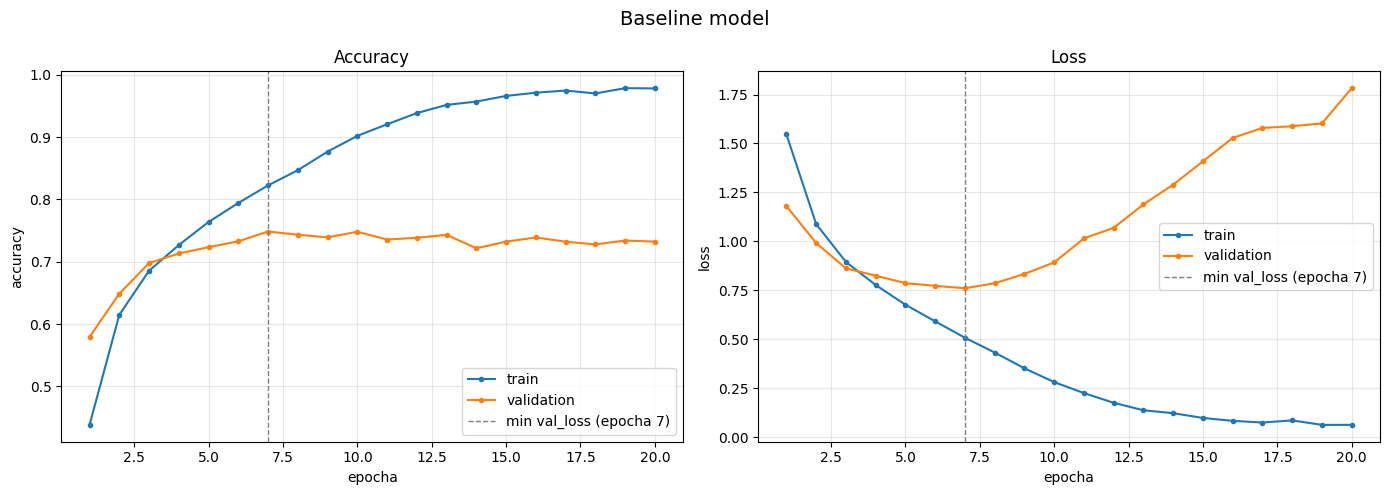

In [ ]:
plot_history(history, 'Baseline model')

### Výsledky baseline modelu

| | Trénovacie dáta | Validačné dáta |
|---|---|---|
| Accuracy – epocha 7 (min. val_loss) | 0.823 | 0.749 |
| Accuracy – epocha 20 | 0.978 | 0.732 |
| Loss – epocha 7 | 0.507 | 0.760 |
| Loss – epocha 20 | 0.062 | 1.783 |

Fázy trénovania:

1. **Epochy 1–5:** trénovacia aj validačná presnosť rastú približne rovnako (validačná z 0.58 na 0.72). Model sa učí všeobecné vizuálne vlastnosti.
2. **Epochy 6–7:** rast validačnej presnosti sa spomaľuje, validačný loss dosahuje minimum 0.760 v 7. epoche.
3. **Epochy 8–20:** trénovacia presnosť ďalej rastie až na 0.98, validačná však stagnuje okolo 0.73–0.74 a validačný loss stúpa z 0.79 na 1.78. Rozdiel medzi trénovacou a validačnou presnosťou sa zväčší na približne 25 p.b.

**Interpretácia:** Približne od 7. epochy sa model pretrénováva. Namiesto všeobecných vzorov si zapamätáva konkrétne trénovacie obrázky. Zaujímavé je, že validačný loss rastie, hoci validačná presnosť zostáva takmer rovnaká. Accuracy berie do úvahy len to, či je trieda s najvyššou pravdepodobnosťou správna, kým cross-entropy loss trestá aj mieru istoty. Pretrénovaný model je čoraz sebavedomejší a pri obrázkoch, ktoré klasifikuje nesprávne, priraďuje nesprávnej triede veľmi vysokú pravdepodobnosť, čo loss výrazne zvyšuje. Validačný loss je preto citlivejším a skorším ukazovateľom pretrénovania ako validačná presnosť, a preto ho neskôr sledujeme pri `EarlyStopping`.

**Záver:** Baseline dosahuje najviac približne 75 % validačnej presnosti, teda menej ako požadovaných 80 %. Dlhšie trénovanie nepomôže, pretože po 7. epoche sa model na validačných dátach už len zhoršuje. Ďalšie experimenty sa preto zameriavajú na regularizáciu (augmentácia dát, Dropout, BatchNormalization, nahradenie `Flatten` vrstvou `GlobalAveragePooling2D`, EarlyStopping) a následne na zväčšenie kapacity siete. Testovacie dáta zatiaľ nepoužívame, aby výsledná testovacia presnosť zostala nestranným odhadom výkonu modelu na nových dátach.

# Riešenie overfittu

Baseline model sa overfittuje približne od 7. epochy a dosahuje ≈ 75 % validačnej presnosti. V nasledujúcich experimentoch postupne pridávame techniky proti pretrénovaniu a sledujeme ich vplyv na validačnú presnosť, validačný loss a rozdiel medzi trénovacou a validačnou presnosťou.

## Augmentácia dát
Pri každej epoche náhodne upraví trénovacie obrázky, takže model nevidí ten istý obrázok dvakrát a nemôže si ho zapamätať.
- `RandomFlip('horizontal')`: mení obraz bez zmeny objektu.
- `RandomTranslation(0.1, 0.1)`: posun najviac o 10%, objekt nemusí byť v strede.

Augmentačné vrstvy sú súčasťou modelu a fungujú len pri trénovaní. Inak je architektúra rovnaká ako baseline, trénujeme 40 epoch.

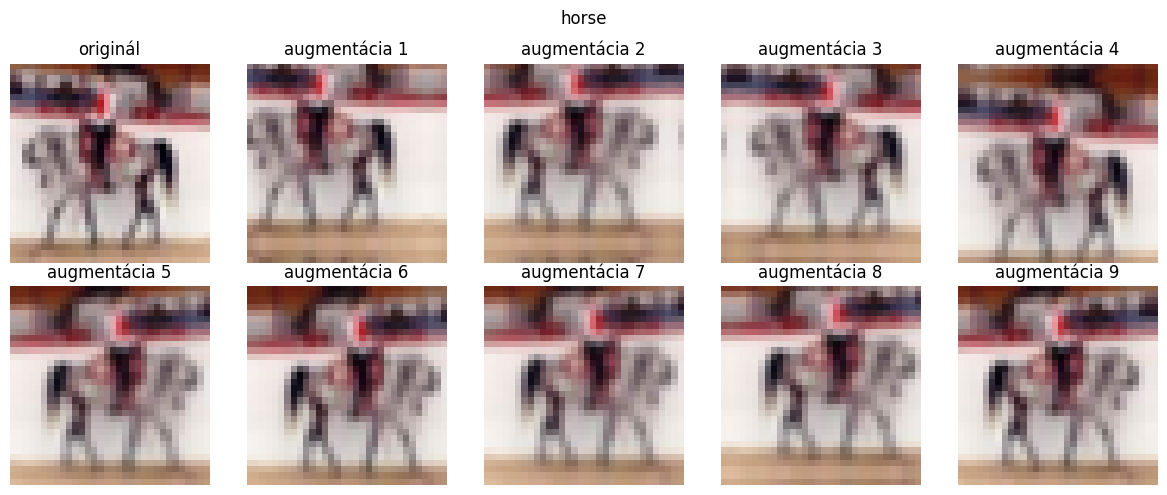

In [ ]:
from keras.layers import RandomFlip, RandomTranslation, BatchNormalization, Activation, Dropout

augmentation = tf.keras.Sequential([
    RandomFlip('horizontal'),
    RandomTranslation(0.1, 0.1, fill_mode='reflect'),
])

sample_img, sample_lbl = next(iter(ds_train))
sample = tf.cast(sample_img, tf.float32)[tf.newaxis] / 255

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    img = sample[0] if i == 0 else augmentation(sample, training=True)[0]
    plt.imshow(img)
    plt.title('originál' if i == 0 else f'augmentácia {i}')
    plt.axis('off')
plt.suptitle(class_names[sample_lbl.numpy()])
plt.tight_layout()
plt.show()

Epoch 1/40
313/313 - 10s - 33ms/step - accuracy: 0.4179 - loss: 1.6029 - val_accuracy: 0.5479 - val_loss: 1.2663
Epoch 2/40
313/313 - 4s - 12ms/step - accuracy: 0.5523 - loss: 1.2549 - val_accuracy: 0.6052 - val_loss: 1.1153
Epoch 3/40
313/313 - 4s - 14ms/step - accuracy: 0.6220 - loss: 1.0775 - val_accuracy: 0.6682 - val_loss: 0.9506
Epoch 4/40
313/313 - 4s - 12ms/step - accuracy: 0.6522 - loss: 0.9897 - val_accuracy: 0.6883 - val_loss: 0.8985
Epoch 5/40
313/313 - 6s - 19ms/step - accuracy: 0.6824 - loss: 0.9082 - val_accuracy: 0.7067 - val_loss: 0.8572
Epoch 6/40
313/313 - 7s - 22ms/step - accuracy: 0.7005 - loss: 0.8504 - val_accuracy: 0.7319 - val_loss: 0.7837
Epoch 7/40
313/313 - 8s - 26ms/step - accuracy: 0.7208 - loss: 0.8015 - val_accuracy: 0.7470 - val_loss: 0.7302
Epoch 8/40
313/313 - 4s - 13ms/step - accuracy: 0.7359 - loss: 0.7538 - val_accuracy: 0.7616 - val_loss: 0.6886
Epoch 9/40
313/313 - 4s - 12ms/step - accuracy: 0.7493 - loss: 0.7195 - val_accuracy: 0.7613 - val_loss

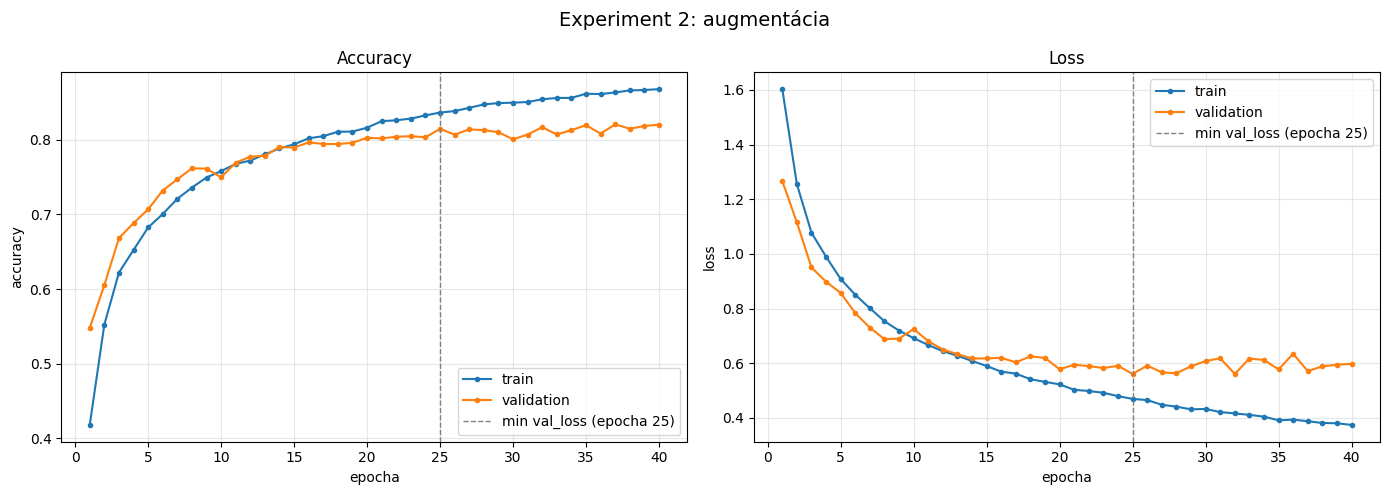

In [ ]:
model_aug = tf.keras.Sequential([
    Input(shape=(32, 32, 3)),
    RandomFlip('horizontal'),
    RandomTranslation(0.1, 0.1, fill_mode='reflect'),

    Conv2D(32, (3, 3), padding='same', activation='relu'),
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model_aug.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_aug = model_aug.fit(train_ds, epochs=40, validation_data=val_ds, verbose=2)

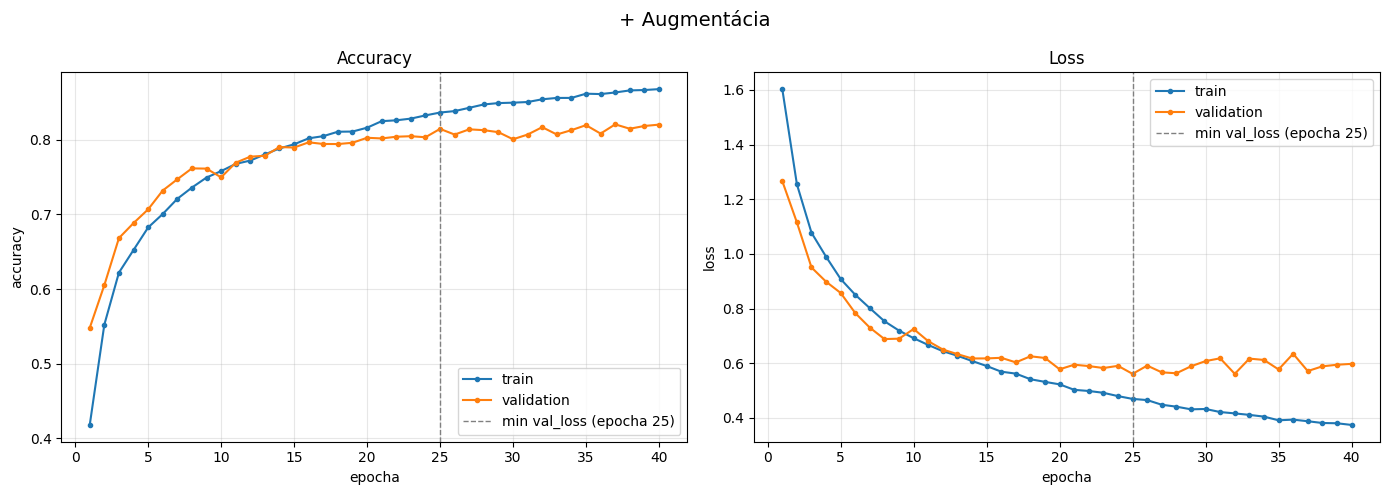

In [ ]:
plot_history(history_aug, '+ Augmentácia')

### Výsledky
Augmentácia overfit výrazne znížila. Validačná presnosť rástla počas celého trénovania až na 0.82 (baseline 0.75), najnižší validačný loss klesol z 0.76 na 0.56. Krivky train a val zostávajú blízko pri sebe, na konci je rozdiel ≈ 5 p.b. (baseline ≈ 25 p.b.). Približne od 25. epochy validačný loss prestáva klesať a rozdiel sa pomaly zväčšuje, takže mierny overfit sa stále objavuje, ale neskôr a slabšie.

## BatchNormalization a Dropout
- **BatchNormalization** normalizuje výstupy vrstvy v rámci batchu, čo stabilizuje a zrýchľuje trénovanie a mierne regularizuje. Dávame ju medzi konvolúciu a ReLU.
- **Dropout** pri trénovaní náhodne vypne časť neurónov (20%, 30% za konvolučnými blokmi, 50% pred výstupnou vrstvou), takže sa sieť nemôže spoliehať na konkrétne neuróny. Najvyšší dropout je pri Dense vrstve, ktorá má najviac parametrov a najviac sa overfittuje.

Obe techniky pridávame naraz, pretože sa bežne používajú spolu. Augmentáciu ponechávame, trénujeme 50 epoch.

In [ ]:
model_bn = tf.keras.Sequential([
    Input(shape=(32, 32, 3)),
    RandomFlip('horizontal'),
    RandomTranslation(0.1, 0.1, fill_mode='reflect'),

    Conv2D(32, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    Conv2D(32, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.2),

    Conv2D(64, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    Conv2D(64, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.3),

    Flatten(),
    Dense(128),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model_bn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_bn = model_bn.fit(train_ds, epochs=50, validation_data=val_ds, verbose=2)

Epoch 1/50
313/313 - 14s - 46ms/step - accuracy: 0.3996 - loss: 1.6930 - val_accuracy: 0.2095 - val_loss: 2.8994
Epoch 2/50
313/313 - 8s - 27ms/step - accuracy: 0.5273 - loss: 1.3137 - val_accuracy: 0.5915 - val_loss: 1.1560
Epoch 3/50
313/313 - 9s - 27ms/step - accuracy: 0.5939 - loss: 1.1453 - val_accuracy: 0.6076 - val_loss: 1.0991
Epoch 4/50
313/313 - 8s - 26ms/step - accuracy: 0.6335 - loss: 1.0429 - val_accuracy: 0.6170 - val_loss: 1.1504
Epoch 5/50
313/313 - 8s - 27ms/step - accuracy: 0.6546 - loss: 0.9840 - val_accuracy: 0.6662 - val_loss: 0.9361
Epoch 6/50
313/313 - 8s - 25ms/step - accuracy: 0.6696 - loss: 0.9405 - val_accuracy: 0.6328 - val_loss: 1.0728
Epoch 7/50
313/313 - 8s - 27ms/step - accuracy: 0.6865 - loss: 0.8969 - val_accuracy: 0.6977 - val_loss: 0.8290
Epoch 8/50
313/313 - 8s - 27ms/step - accuracy: 0.6957 - loss: 0.8701 - val_accuracy: 0.7198 - val_loss: 0.7940
Epoch 9/50
313/313 - 8s - 26ms/step - accuracy: 0.7102 - loss: 0.8402 - val_accuracy: 0.7439 - val_loss

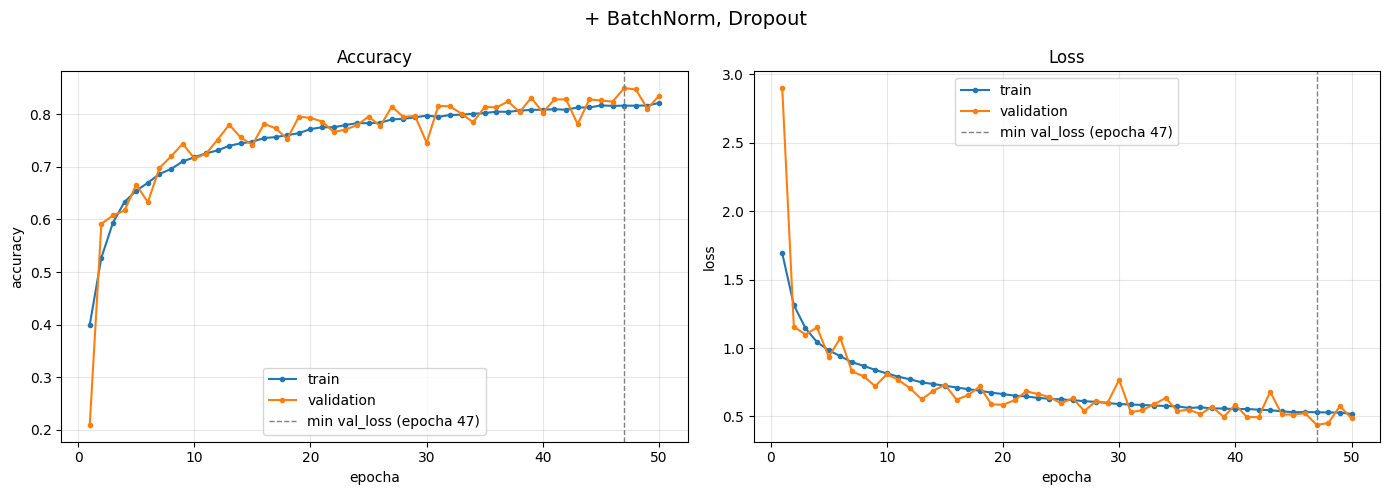

In [ ]:
plot_history(history_bn, '+ BatchNorm, Dropout')

### Výsledky
Najlepšia validačná presnosť je ≈ 85% (47. epocha) a validačný loss 0.44. Trénovacia presnosť je na konci nižšia ako validačná (0.82 vs 0.835), pretože dropout a augmentácia fungujú len pri trénovaní a model sa tak učí na ťažšej úlohe, než na akej sa vyhodnocuje. Overfit tu už nie je.

Validačné krivky sú nestabilné, presnosť skáče medzi 0.78 a 0.85 z epochy na epochu. BatchNormalization pri vyhodnocovaní používa kĺzavé priemery štatistík, a pri konštantnom learning rate (0.001) sa váhy stále výrazne menia, takže tieto priemery za nimi zaostávajú. Z rovnakého dôvodu je presnosť v 1. epoche len 0.21.

Trénovacia presnosť na konci stále rastie, model teda nie je dotrénovaný. Ďalej preto skúšame znižovať learning rate a zväčšovať sieť.

## ReduceLROnPlateau a EarlyStopping
Architektúra je rovnaká, meníme len priebeh trénovania.
- `ReduceLROnPlateau`: keď sa validačný loss 5 epoch nezlepší, zníži learning rate na polovicu. Menšie kroky ku koncu trénovania stabilizujú model a umožnia mu doladiť váhy.
- `EarlyStopping`: keď sa validačný loss 15 epoch nezlepší, trénovanie zastaví a vráti váhy z najlepšej epochy. Nemusíme tak odhadovať počet epoch.

Maximálny počet epoch nastavujeme na 100.

Epoch 1/100
313/313 - 13s - 42ms/step - accuracy: 0.4019 - loss: 1.6886 - val_accuracy: 0.2208 - val_loss: 2.5225 - learning_rate: 0.0010
Epoch 2/100
313/313 - 9s - 30ms/step - accuracy: 0.5408 - loss: 1.2784 - val_accuracy: 0.5674 - val_loss: 1.2034 - learning_rate: 0.0010
Epoch 3/100
313/313 - 8s - 26ms/step - accuracy: 0.6020 - loss: 1.1276 - val_accuracy: 0.6235 - val_loss: 1.0603 - learning_rate: 0.0010
Epoch 4/100
313/313 - 8s - 27ms/step - accuracy: 0.6308 - loss: 1.0389 - val_accuracy: 0.6647 - val_loss: 0.9371 - learning_rate: 0.0010
Epoch 5/100
313/313 - 9s - 27ms/step - accuracy: 0.6534 - loss: 0.9838 - val_accuracy: 0.6385 - val_loss: 1.0224 - learning_rate: 0.0010
Epoch 6/100
313/313 - 8s - 26ms/step - accuracy: 0.6719 - loss: 0.9351 - val_accuracy: 0.7127 - val_loss: 0.7939 - learning_rate: 0.0010
Epoch 7/100
313/313 - 9s - 27ms/step - accuracy: 0.6848 - loss: 0.8939 - val_accuracy: 0.7084 - val_loss: 0.8177 - learning_rate: 0.0010
Epoch 8/100
313/313 - 8s - 26ms/step - a

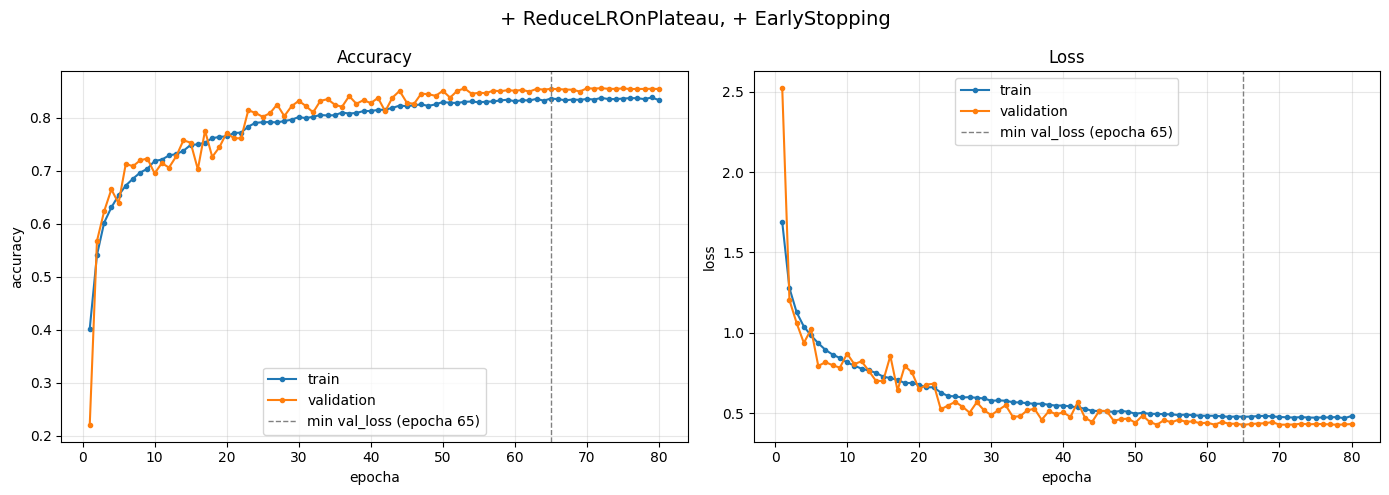

In [ ]:
from keras.callbacks import ReduceLROnPlateau, EarlyStopping

model_lr = tf.keras.models.clone_model(model_bn)
model_lr.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=1),
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
]

history_lr = model_lr.fit(train_ds, epochs=100, validation_data=val_ds, callbacks=callbacks, verbose=2)

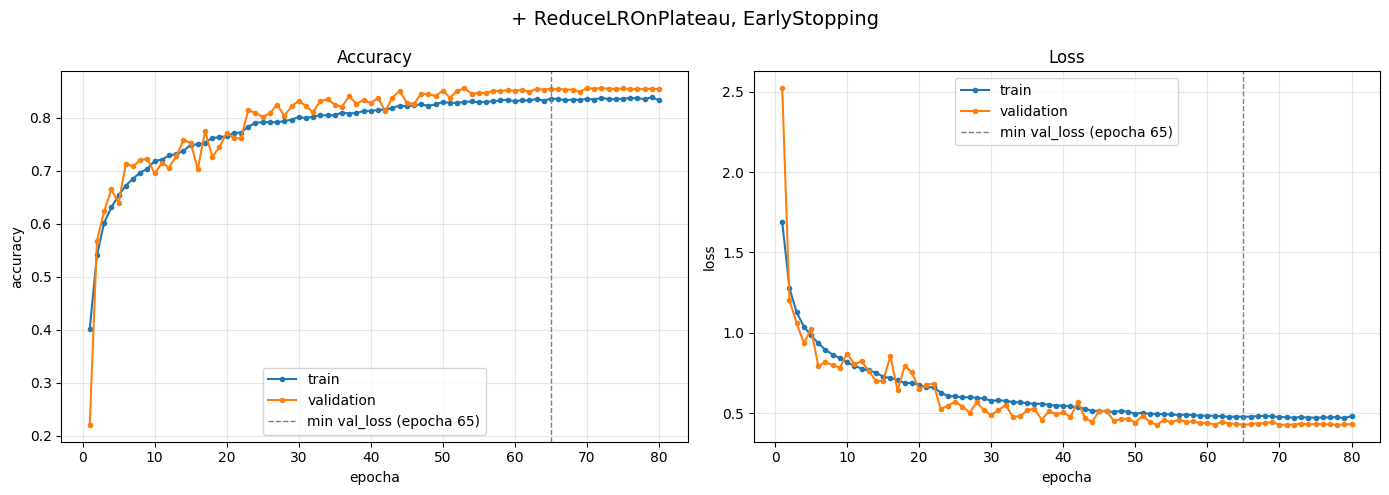

In [ ]:
plot_history(history_lr, '+ ReduceLROnPlateau, EarlyStopping')

### Výsledky
Najlepšia validačná presnosť je ≈ 85.4% (65. epocha), validačný loss 0.43. Oproti predchádzajúcemu experimentu sa presnosť takmer nezmenila, ale trénovanie je oveľa stabilnejšie. Približne od 50. epochy sa krivky nemenia ani pri ďalšom znižovaní learning rate a trénovacia presnosť zostáva okolo 0.83. Model teda narazil na hranicu svojej kapacity a na lepší výsledok potrebuje väčšiu sieť. EarlyStopping zastavil trénovanie v 80. epoche a vrátil váhy z 65. epochy.

## Hlbšia sieť a GlobalAveragePooling
Keďže overfit už nie je problém a trénovacia presnosť stále rastie, model potrebuje väčšiu kapacitu.
- Pridávame tretí konvolučný blok a zdvojnásobujeme počet filtrov (64, 128, 256). Hlbšie vrstvy dokážu rozpoznať zložitejšie tvary a časti objektov.
- Dropout rastie s hĺbkou siete (0.2, 0.3, 0.4).
- `Flatten` a `Dense(128)` nahrádzame vrstvou `GlobalAveragePooling2D`, ktorá každú z 256 máp príznakov spriemeruje na jedno číslo. Odpadá tak plne prepojená vrstva, ktorá mala v baseline 89 % všetkých parametrov.

Callbacky ponechávame.

In [ ]:
from keras.layers import GlobalAveragePooling2D

model_deep = tf.keras.Sequential([
    Input(shape=(32, 32, 3)),
    RandomFlip('horizontal'),
    RandomTranslation(0.1, 0.1, fill_mode='reflect'),

    Conv2D(64, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    Conv2D(64, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.2),

    Conv2D(128, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    Conv2D(128, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.3),

    Conv2D(256, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    Conv2D(256, (3, 3), padding='same'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.4),

    GlobalAveragePooling2D(),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model_deep.summary()

callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=1),
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
]

model_deep.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_deep = model_deep.fit(train_ds, epochs=100, validation_data=val_ds, callbacks=callbacks, verbose=2)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_4 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_4            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 8, 8, 256)      │       590,08

 Total params: 1,151,562 (4.39 MB)

 Trainable params: 1,149,770 (4.39 MB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/100
313/313 - 29s - 94ms/step - accuracy: 0.4014 - loss: 1.6833 - val_accuracy: 0.1083 - val_loss: 3.2348 - learning_rate: 0.0010
Epoch 2/100
313/313 - 33s - 104ms/step - accuracy: 0.5604 - loss: 1.2162 - val_accuracy: 0.5390 - val_loss: 1.3116 - learning_rate: 0.0010
Epoch 3/100
313/313 - 18s - 58ms/step - accuracy: 0.6381 - loss: 1.0245 - val_accuracy: 0.6047 - val_loss: 1.0817 - learning_rate: 0.0010
Epoch 4/100
313/313 - 18s - 57ms/step - accuracy: 0.6816 - loss: 0.9060 - val_accuracy: 0.5861 - val_loss: 1.2753 - learning_rate: 0.0010
Epoch 5/100
313/313 - 17s - 56ms/step - accuracy: 0.7168 - loss: 0.8106 - val_accuracy: 0.6661 - val_loss: 1.0034 - learning_rate: 0.0010
Epoch 6/100
313/313 - 17s - 55ms/step - accuracy: 0.7391 - loss: 0.7538 - val_accuracy: 0.6702 - val_loss: 1.0385 - learning_rate: 0.0010
Epoch 7/100
313/313 - 18s - 57ms/step - accuracy: 0.7558 - loss: 0.7102 - val_accuracy: 0.6285 - val_loss: 1.1570 - learning_rate: 0.0010
Epoch 8/100
313/313 - 18s - 56ms/

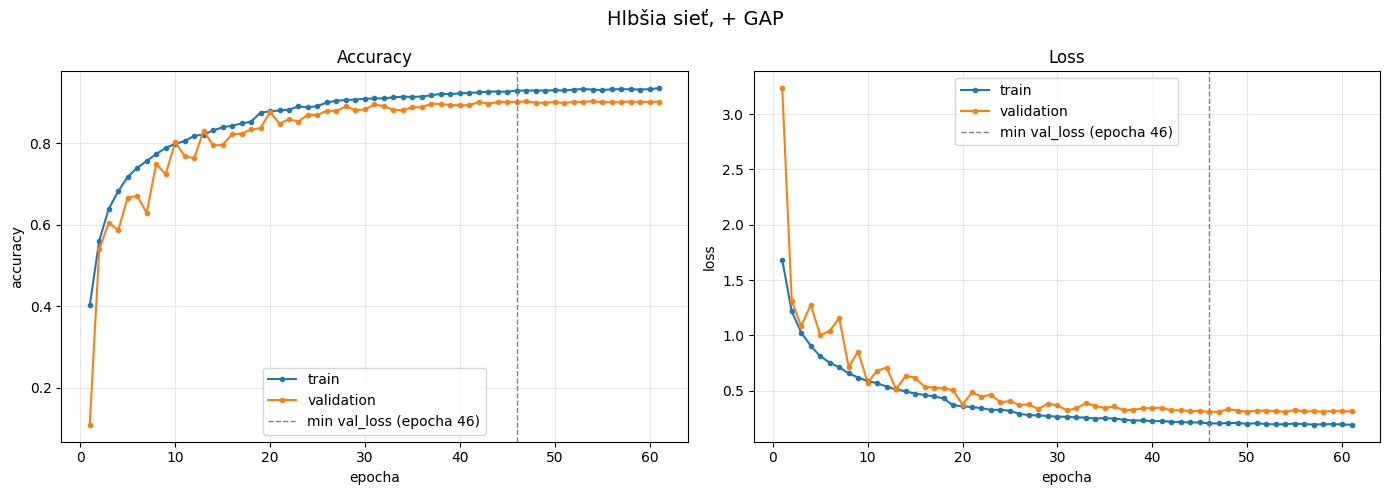

In [ ]:
plot_history(history_deep, 'Hlbšia sieť, + GAP')

### Výsledky
Hlbšia sieť dosiahla najlepšiu validačnú presnosť ≈ 90% (46. epocha) a validačný loss 0.31, o 4.7 p.b. viac ako predchádzajúca architektúra. Sieť má 1.15 mil. parametrov, takmer všetky v konvolučných vrstvách. Výstupná Dense vrstva má len 2 570 parametrov, kým v baseline mala plne prepojená časť 89% všetkých parametrov.

Najväčší skok opäť nastal po prvom znížení learning rate. Trénovacia presnosť je tentokrát vyššia ako validačná (0.93 vs 0.90), pretože väčšia sieť dokáže trénovacie dáta lepšie pokryť aj s dropoutom a augmentáciou. Rozdiel ≈ 3 p.b. je však malý a validačný loss ku koncu už nerastie, takže ide len o mierny overfit, ktorý EarlyStopping drží pod kontrolou. Trénovanie sa zastavilo v 61. epoche, použité sú váhy zo 46. epochy.

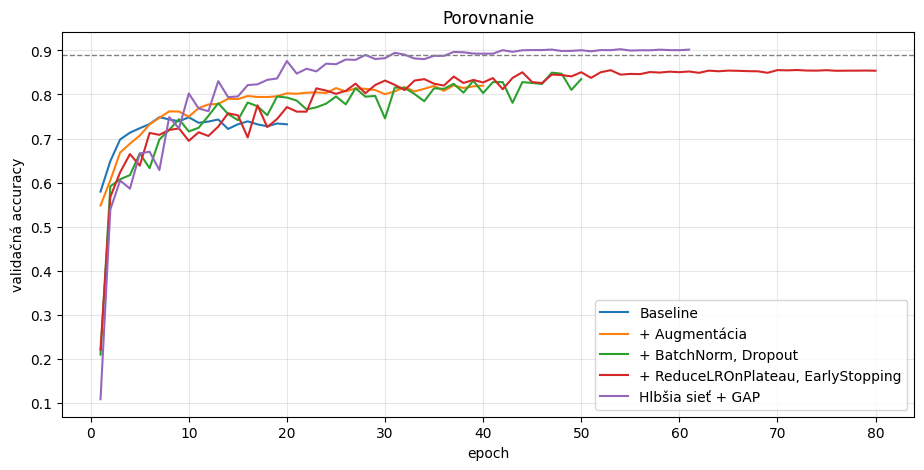

In [ ]:
plt.figure(figsize=(11, 5))
for h, name in [(history, 'Baseline'), (history_aug, '+ Augmentácia'), (history_bn, '+ BatchNorm, Dropout'),
                (history_lr, '+ ReduceLROnPlateau, EarlyStopping'), (history_deep, 'Hlbšia sieť + GAP')]:
    plt.plot(range(1, len(h.history['val_accuracy']) + 1), h.history['val_accuracy'], label=name)
plt.axhline(0.89, color='gray', ls='--', lw=1)
plt.xlabel('epoch'); plt.ylabel('validačná accuracy')
plt.title('Porovnanie')
plt.grid(alpha=0.3); plt.legend()
plt.show()

## Porovnanie

| Experiment | Parametre | Najlepšia epocha | Train acc | Val acc | Val loss |
|---|---|---|---|---|---|
| Baseline | 591 274 | 7 | 0.823 | 0.749 | 0.760 |
| + Augmentácia | 591 274 | 25 | 0.836 | 0.815 | 0.561 |
| + BatchNorm, Dropout | 592 554 | 47 | 0.816 | 0.850 | 0.439 |
| + ReduceLROnPlateau, EarlyStopping | 592 554 | 65 | 0.836 | 0.854 | 0.427 |
| Hlbšia sieť + GAP | 1 151 562 | 46 | 0.929 | 0.901 | 0.308 |

Hodnoty sú z epochy s najnižším validačným lossom.

Augmentácia odstránila väčšinu overfitu, BatchNorm a Dropout odstránil zvyšok, znižovanie learning rate stabilizovalo trénovanie a ukázalo, že menšia sieť narazila na hranicu kapacity, a hlbšia sieť s GlobalAveragePooling túto hranicu posunula.

Ako finálnu architektúru volíme **hlbšiu sieť s GlobalAveragePooling**. Má najvyššiu validačnú presnosť, najnižší validačný loss a malý rozdiel medzi trénovacou a validačnou presnosťou.

# Finálny model
Finálny model má architektúru z posledného experimentu a trénuje sa od začiatku s rovnakými callbackmi. Navyše logujeme pre TensorBoard.

In [ ]:
from keras.callbacks import TensorBoard

model_final = tf.keras.models.clone_model(model_deep)
model_final.summary()

callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=1),
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
    TensorBoard(log_dir='/content/drive/MyDrive/4IZ175/logs', histogram_freq=0, write_graph=False),
]

model_final.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_final = model_final.fit(train_ds, epochs=100, validation_data=val_ds, callbacks=callbacks, verbose=2)

model_final.save('/content/drive/MyDrive/4IZ175/Samaš-Martin-Snížek-Martin-obraz.keras')

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_4 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_4            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 8, 8, 256)      │       590,08

 Total params: 3,451,104 (13.16 MB)

 Trainable params: 1,149,770 (4.39 MB)

 Non-trainable params: 1,792 (7.00 KB)

 Optimizer params: 2,299,542 (8.77 MB)

Epoch 1/100
313/313 - 23s - 72ms/step - accuracy: 0.3807 - loss: 1.7156 - val_accuracy: 0.1023 - val_loss: 3.9713 - learning_rate: 0.0010
Epoch 2/100
313/313 - 19s - 62ms/step - accuracy: 0.5569 - loss: 1.2302 - val_accuracy: 0.6232 - val_loss: 1.0452 - learning_rate: 0.0010
Epoch 3/100
313/313 - 18s - 56ms/step - accuracy: 0.6290 - loss: 1.0420 - val_accuracy: 0.5743 - val_loss: 1.3052 - learning_rate: 0.0010
Epoch 4/100
313/313 - 18s - 57ms/step - accuracy: 0.6727 - loss: 0.9218 - val_accuracy: 0.5268 - val_loss: 1.6090 - learning_rate: 0.0010
Epoch 5/100
313/313 - 19s - 61ms/step - accuracy: 0.7114 - loss: 0.8268 - val_accuracy: 0.6900 - val_loss: 0.8618 - learning_rate: 0.0010
Epoch 6/100
313/313 - 18s - 59ms/step - accuracy: 0.7377 - loss: 0.7516 - val_accuracy: 0.6875 - val_loss: 0.8709 - learning_rate: 0.0010
Epoch 7/100
313/313 - 19s - 59ms/step - accuracy: 0.7543 - loss: 0.7107 - val_accuracy: 0.7267 - val_loss: 0.7835 - learning_rate: 0.0010
Epoch 8/100
313/313 - 18s - 57ms/s

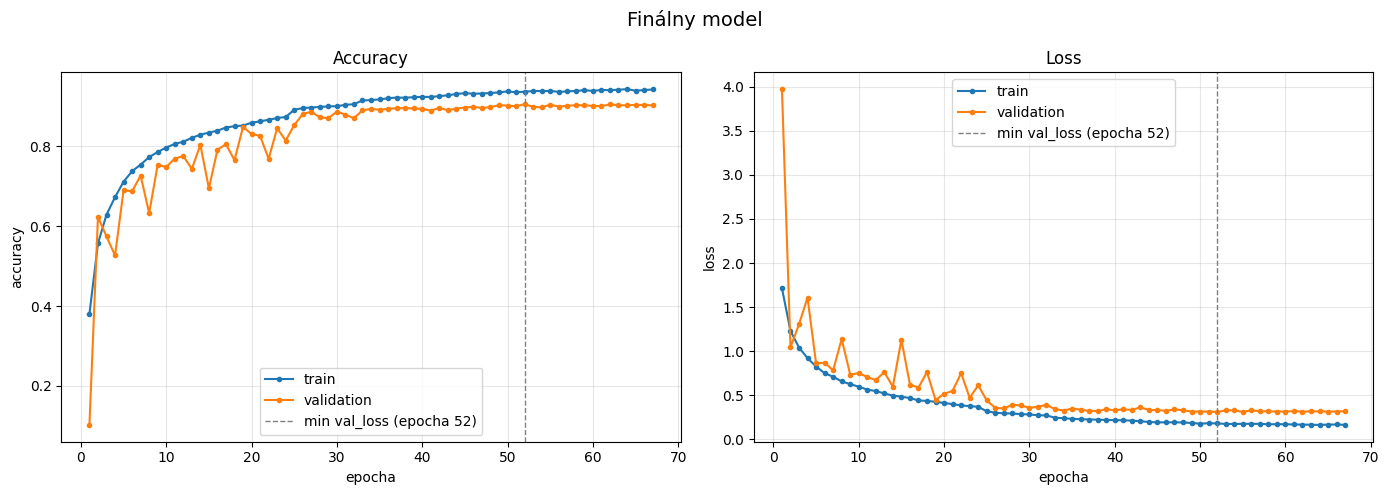

In [ ]:
plot_history(history_final, 'Finálny model')

### Výsledky
Finálny model dosiahol najnižší validačný loss 0.312 v 52. epoche, s validačnou presnosťou 0.906 a trénovacou 0.937. Trénovanie sa zastavilo v 67. epoche a použité sú váhy z 52. epochy. Do prvého zníženia learning rate v 24. epoche validačná presnosť výrazne skákala (0.69 – 0.85), potom sa ustálila a postupne vystúpila nad 0.90.

# Vyhodnotenie na test_ds
Testovacie dáta používame prvýkrát až teraz, na finálnom modeli.

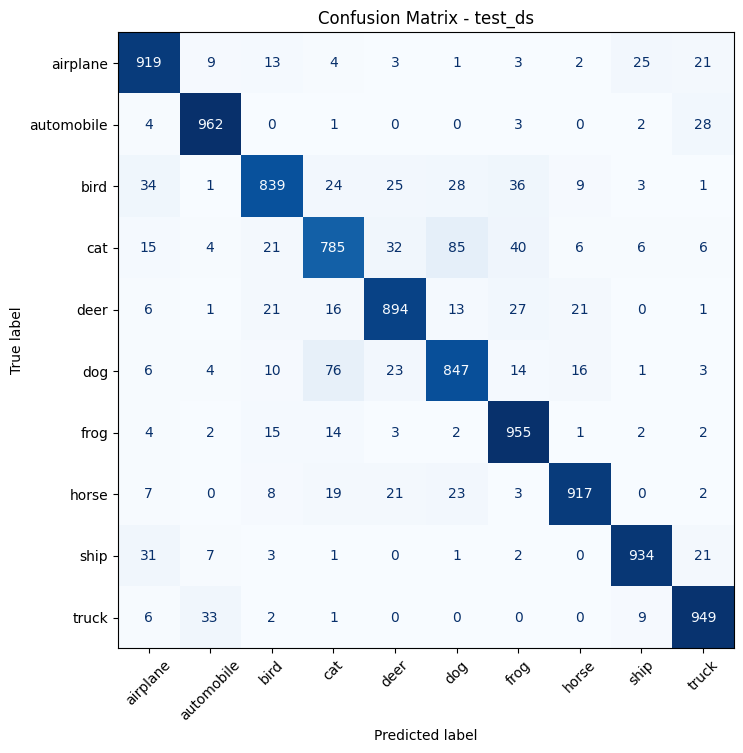

              precision    recall  f1-score   support

    airplane      0.891     0.919     0.905      1000
  automobile      0.940     0.962     0.951      1000
        bird      0.900     0.839     0.869      1000
         cat      0.834     0.785     0.809      1000
        deer      0.893     0.894     0.894      1000
         dog      0.847     0.847     0.847      1000
        frog      0.882     0.955     0.917      1000
       horse      0.943     0.917     0.930      1000
        ship      0.951     0.934     0.942      1000
       truck      0.918     0.949     0.933      1000

    accuracy                          0.900     10000
   macro avg      0.900     0.900     0.900     10000
weighted avg      0.900     0.900     0.900     10000



In [ ]:
y_prob = model_final.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.concatenate([y.numpy() for _, y in test_ds])

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
plt.title('Confusion Matrix - test_ds')
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

### Výsledky na testovacích dátach
Testovacia presnosť finálneho modelu je **0.900**, čo zodpovedá validačnej presnosti (0.906). Validačná množina bola teda dobrým odhadom výkonu na nových dátach.

Najlepšie rozpoznávané triedy sú automobile (recall 0.962), frog (0.955) a truck (0.949), najhoršie cat (0.785), bird (0.839) a dog (0.847).

Model takmer nezamieňa zvieratá s dopravnými prostriedkami (s výnimkou bird -> airplane), chyby vznikajú hlavne v rámci týchto dvoch skupín.

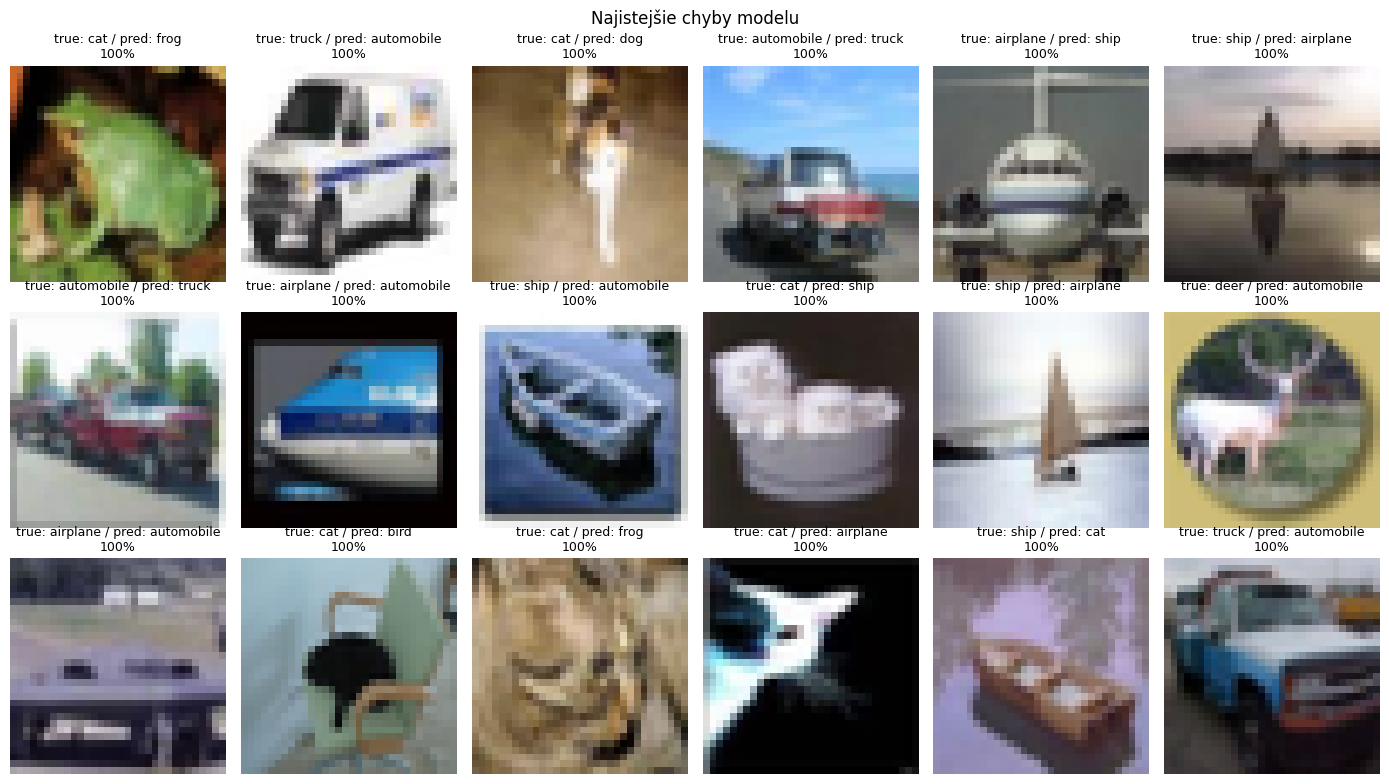

In [ ]:
wrong = np.where(y_pred != y_true)[0]
conf = y_prob[wrong, y_pred[wrong]]
top = wrong[np.argsort(-conf)][:18]
test_images = np.concatenate([x.numpy() for x, _ in test_ds])

plt.figure(figsize=(14, 8))
for i, idx in enumerate(top):
    plt.subplot(3, 6, i + 1)
    plt.imshow(test_images[idx])
    plt.title(f'true: {class_names[y_true[idx]]} / pred: {class_names[y_pred[idx]]}\n{y_prob[idx, y_pred[idx]]:.0%}', fontsize=9)
    plt.axis('off')
plt.suptitle('Najistejšie chyby modelu')
plt.tight_layout()
plt.show()

### Najistejšie chyby
Zobrazených je 18 nesprávne klasifikovaných obrázkov, pri ktorých podla confidence.
- **Nejednoznačné triedy:** dodávky a pickupy (truck - automobile), ktoré sami máme problém zaradiť.
- **Chybné labely:** napr. prvý obrázok.
- **Netypické obrázky:** uhol pohľadu, rám alebo čierny okraj, malý alebo neúplný objekt.

Pri všetkých týchto chybách má model istotu takmer 100 %. Pri nezvyčajných obrázkoch je teda prehnane sebavedomý.